In [1]:
import os
import numpy as np
import pandas as pd
import tifffile
import glob

import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline


In [30]:
def normalize_spectra(spectra):
    """Min-max normalize spectra (n_samples, n_channels) or (n_channels,)"""
    if spectra.ndim == 1:
        min_v = np.min(spectra)
        max_v = np.max(spectra)
        return (spectra - min_v) / (max_v - min_v + 1e-10)
    else:
        min_v = np.min(spectra, axis=1, keepdims=True)
        max_v = np.max(spectra, axis=1, keepdims=True)
        return (spectra - min_v) / (max_v - min_v + 1e-10)

def load_reference_spectra(csv_path, wn_start, wn_end, num_samp):
    """Load and interpolate reference spectra from CSV."""
    df = pd.read_csv(csv_path)
    df = df.dropna(axis='columns', how='all')
    
    col_names = df.columns
    num_mol = len(col_names) // 2
    
    target_wn = np.linspace(wn_start, wn_end, num_samp)
    ref_spectra = {}
    
    for i in range(0, len(col_names), 2):
        name = col_names[i].strip()
        mol_wn = df.iloc[:, i].values
        mol_int = df.iloc[:, i+1].values
        
        # Remove NaNs
        valid = ~np.isnan(mol_wn) & ~np.isnan(mol_int)
        mol_wn = mol_wn[valid]
        mol_int = mol_int[valid]
        
        if len(mol_wn) < 2:
            continue
            
        # Sort by wavenumber if needed
        idx = np.argsort(mol_wn)
        mol_wn = mol_wn[idx]
        mol_int = mol_int[idx]
        
        # Interpolate
        try:
            cs = CubicSpline(mol_wn, mol_int, extrapolate=True)
            interp_int = cs(target_wn)
            ref_spectra[name] = normalize_spectra(interp_int)
        except Exception as e:
            print(f"Failed to interpolate {name}: {e}")
            
    return ref_spectra

def calculate_sam(query, references):
    """
    Calculate Spectral Angle (SAM) between query and references.
    query: (n_pixels, n_channels)
    references: (n_molecules, n_channels)
    Returns: (n_pixels, n_molecules) angles in radians
    """
    # Normalize vectors to unit length
    q_norm = query / (np.linalg.norm(query, axis=1, keepdims=True) + 1e-10)
    r_norm = references / (np.linalg.norm(references, axis=1, keepdims=True) + 1e-10)
    
    # Dot product
    cos_theta = np.dot(q_norm, r_norm.T)
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    
    return np.arccos(cos_theta) # Small angles mean very similar (good matches) 

def estimate_best_shift(image_mean, background_ref, config):
    """
    Estimate best global shift by correlating background_ref with image_mean.
    Window: High intensity region (> 2800 cm^-1).
    """
    best_corr = -1
    best_shift = 0
    
    # We focus on the region after CH_START (the CH stretch region)
    region_mask = slice(config['ch_start'], None)
    img_region = image_mean[region_mask]
    img_region = (img_region - np.mean(img_region)) / (np.std(img_region) + 1e-10)
    
    for s in range(-config["max_shift_ch"], config["max_shift_ch"] + 1):
        # Shift background ref
        shifted_ref = np.zeros_like(background_ref)
        if s > 0:
            shifted_ref[s:] = background_ref[:-s]
        elif s < 0:
            shifted_ref[:s] = background_ref[-s:]
        else:
            shifted_ref = background_ref
            
        ref_region = shifted_ref[region_mask]
        ref_region = (ref_region - np.mean(ref_region)) / (np.std(ref_region) + 1e-10)
        
        corr = np.mean(img_region * ref_region)
        if corr > best_corr:
            best_corr = corr
            best_shift = s
            
    return best_shift

def plot_diagnostic_samples(out_dir, image_mmap, shifted_ref_matrix, mol_names, config, ch_order_flip=False):
    """
    Pick best, worst, and random matches to visualize SAM performance for large images.
    Since angles/similarity are not globally stored, we perform a quick scan of 1M random pixels.
    """
    print("Generating diagnostic plots from sampled pixels...")
    h, w = image_mmap.shape[-2], image_mmap.shape[-1]
    n_pixels = h * w
    
    # Sample 1M pixels (or all if fewer)
    sample_size = min(n_pixels, 1_000_000)
    indices = np.random.choice(n_pixels, sample_size, replace=False)
    
    # Load and process sample
    image_flat = image_mmap.reshape(image_mmap.shape[0], -1).T
    chunk = image_flat[indices]
    if ch_order_flip:
        chunk = np.flip(chunk, axis=1)
    chunk = chunk.astype(np.float32)
    
    # Baseline subtraction
    silent_baseline = np.mean(chunk[:, :config['ch_start']], axis=1, keepdims=True)
    chunk_proc = chunk - silent_baseline
    
    # SAM
    angles = calculate_sam(chunk_proc, shifted_ref_matrix)
    similarity = 1.0 - (angles / np.pi)
    best_match_idx = np.argmin(angles, axis=1)
    best_similarity = np.max(similarity, axis=1)
    
    # Pick 3 samples from the chunk
    diag_indices = [
        np.argmax(best_similarity), # Best in sample
        np.argmin(best_similarity), # Worst in sample
        np.random.randint(0, sample_size) # Random in sample
    ]
    diag_labels = ['Best_Match', 'Worst_Match', 'Random_Match']
    
    wn = np.linspace(config['wn_start'], config['wn_end'], config['num_samples'])

    results = {}
    
    for local_idx, label in zip(diag_indices, diag_labels):
        global_p_idx = indices[local_idx]
        q = chunk_proc[local_idx]
        m_idx = best_match_idx[local_idx]
        r = shifted_ref_matrix[m_idx]
        angle = angles[local_idx, m_idx]
        
        # Unit normalization for visual comparison
        q_unit = q / (np.linalg.norm(q) + 1e-10)
        r_unit = r / (np.linalg.norm(r) + 1e-10)
        
        # plt.figure(figsize=(10, 5))
        # plt.plot(wn, q_unit, 'b-', label='Pixel Spectrum (Unit Vector)')
        # plt.plot(wn, r_unit, 'r--', label=f'Matched Ref: {mol_names[m_idx]} (Unit Vector)')
        
        # plt.title(f"{label} (Pixel {global_p_idx})\nAngle: {angle:.4f} rad ({np.degrees(angle):.2f} deg)")
        # plt.xlabel("Wavenumber (cm^-1)")
        # plt.ylabel("Unit Normalized Intensity")
        # plt.legend()
        # plt.grid(True, alpha=0.3)
        # plt.show()
        
        # out_path = os.path.join(out_dir, f"diagnostic_{label.lower()}.png")
        # plt.savefig(out_path, dpi=100)
        # plt.close()

        results[label] = [q_unit, r_unit]
        results[label+" mol"] = mol_names[m_idx]
        results[label+" sim"] = best_similarity[local_idx]
        results[label+" idx"] = local_idx
        
    results['sim'] = similarity
        
    return results # Return samples for summary plot if needed

In [3]:
CONFIG = {
    'wn_start':2700,
    'wn_end':3100,
    'num_samples':61,
    'max_shift_cm':30,

    'img_dir': "D:\\ADATA Backup\\Lipid Reference Library\\processed-data",
    'spectra_csv': r'C:\Users\jvill\OneDrive\Documents\GitHub\hsi_machine_learning\unprocessed_data\averaged_spectra.csv',
}
WN_STEP = (CONFIG['wn_end'] - CONFIG['wn_start']) / (CONFIG['num_samples'] - 1)
MAX_SHIFT_CHANNELS = int(np.ceil(CONFIG['max_shift_cm'] / WN_STEP))
CH_START = int((2800 - CONFIG['wn_start']) / WN_STEP)
CONFIG['ch_start'] = CH_START
CONFIG['max_shift_ch'] = MAX_SHIFT_CHANNELS

Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
PE Mix
PI Mix
PS Mix
PG Mix
DOPC
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
18:1 Cholesterol Ester
Cholesterol (ovine)
PG Mix
PI Mix
PE Mix
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
Cholesterol (ovine)
18:1 Cholesterol Ester
PE Mix
PG Mix
PI Mix
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
DOPC
PE Mix
PC Mix
PS Mix
PI Mix
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
PE Mix
DOPC
PC Mix
PI Mix
PS Mix
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
DOPE
18:1 LPA
PG Mix
PS Mix
PC Mix
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
PE Mix
PI Mix
PS Mix
PG Mix
18:1 LPA
Generating diagnostic plots from sampled pixels...
Top 5 similarity_values:
PE Mix
PI Mix
PG Mix
PS Mix
18:1 Cholesterol Ester


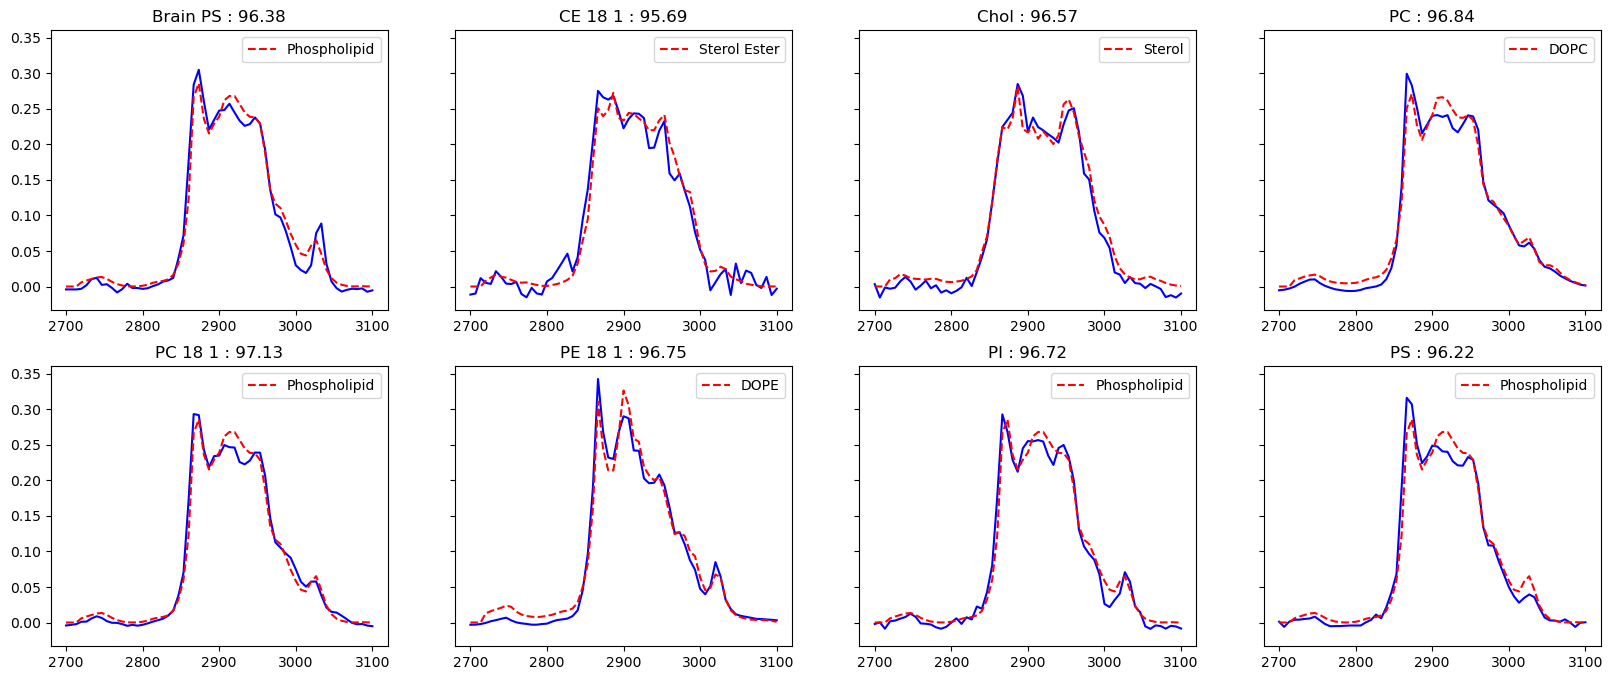

In [38]:
base_dir = os.path.dirname(CONFIG['img_dir'])
output_dir = os.path.join(base_dir, 'img_outputs')
os.makedirs(output_dir, exist_ok=True)

ref_dict = load_reference_spectra(
    CONFIG['spectra_csv'], 
    CONFIG['wn_start'], 
    CONFIG['wn_end'], 
    CONFIG['num_samples']
)


bg_ref_name = 'PC Mix'
if bg_ref_name not in ref_dict:
    bg_ref_name = next((k for k in ref_dict.keys() if 'background' in k.lower()), list(ref_dict.keys())[0])
    print(f"Warning: '{bg_ref_name}' not found, using '{bg_ref_name}' as calibration anchor.")
bg_ref = ref_dict[bg_ref_name]
mol_names = sorted(list(ref_dict.keys()))
mol_names = sorted(list(ref_dict.keys()))
ref_matrix = np.array([ref_dict[name] for name in mol_names])

img_dict = {}
img_files = glob.glob(os.path.join(CONFIG['img_dir'],'*.tif'))

groups = {
    "PE Mix": "Phospholipid",
    "Cholesterol (ovine)": "Sterol",
    '18:1 Cholesterol Ester': "Sterol Ester"
}

select_images = [
    "Brain_PS",
    "CE_18_1",
    "Chol",
    "PC",
    "PC_18_1",
    "PE_18_1",
    "PI",
    "PS",
]

img_files = [img_file for img_file in img_files if os.path.basename(img_file).replace('.tif', '') in select_images]
fig, axes = plt.subplots(ncols=len(img_files)//2, nrows=2, sharey=True, figsize=(20, 8), squeeze=False)
axes_flat = axes.flatten()

for i, ax in enumerate(axes_flat):
    img_name = os.path.basename(img_files[i]).replace('.tif', '')


    img = tifffile.imread(img_files[i])
    std = img.std(0)
    threshold = np.percentile(std, 50)
    mask = np.where(std < threshold, False, True)
    img = np.flip(img * mask[np.newaxis, :, :], 0)
    
    mean_spec = normalize_spectra(np.mean(img, (1,2)))
    
    if i == 0:
        best_shift = estimate_best_shift(mean_spec, bg_ref, CONFIG)
        
        # Apply shift to references
        shifted_ref_matrix = np.zeros_like(ref_matrix)
        
        # FIX: Changed inner loop index from 'i' to 'j' to avoid overwriting the outer 'i'
        for j in range(len(mol_names)):
            if best_shift > 0:
                shifted_ref_matrix[j, best_shift:] = ref_matrix[j, :-best_shift]
            elif best_shift < 0:
                shifted_ref_matrix[j, :best_shift] = ref_matrix[j, -best_shift:]
            else:
                shifted_ref_matrix[j] = ref_matrix[j]
                
        shifted_ref_dict = {}
        for mol_name, spectra in ref_dict.items():
            temp = np.zeros_like(spectra)
            if best_shift > 0:
                temp[best_shift:] = spectra[:-best_shift]
            elif best_shift < 0:
                temp[:best_shift] = spectra[-best_shift:]
            else:
                temp = spectra
            shifted_ref_dict[mol_name] = temp
            
    img_dict[img_name] = mean_spec
    
    results = plot_diagnostic_samples(
        out_dir=output_dir,
        image_mmap=img,
        shifted_ref_matrix=shifted_ref_matrix,
        mol_names=mol_names,
        config=CONFIG
    )
    
    wn = np.linspace(CONFIG['wn_start'], CONFIG['wn_end'], CONFIG['num_samples'])
    q_unit = results['Best_Match'][0]
    r_unit = results['Best_Match'][1]
    top_n = np.argsort(results['sim'][results['Best_Match idx']])[-5:][::-1]

    print(f"Top 5 similarity_values:")
    for j in top_n: 
        print(mol_names[j])
    # These will now correctly target the individual subplot 'ax'
    ax.plot(wn, q_unit, 'b-')
    ax.plot(wn, r_unit, 'r--', label=f'{groups.get(results["Best_Match mol"],results["Best_Match mol"])}')
    ax.set_title(f'{img_name.replace("_"," ")} : {results["Best_Match sim"]*100:.2f}')  # Clean addition to tell your subplots apart
    ax.legend()

# plt.tight_layout() # Prevents label clipping
plt.show()

In [ ]:
groups = {
    "PE Mix": "Phospholipid",
    "Cholesterol (ovine)": "Sterol",
    '18:1 Cholesterol Ester': "Sterol Ester"
}

select_images = [
    "Brain_PS",
    "CE_18_1",
    "Chol",
    "PC",
    "PC_18_1",
    "PE_18_1",
    "PI",
    "PS",
]

img_display = {
    "Brain_PS": "Brain PS",
    "CE_18_1": "18:1 Chol.E.",
    "Chol": "Chol",
    "PC",
    "PC_18_1",
    "PE_18_1",
    "PI",
    "PS",
}

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 5.86308480e-03,
       8.38935470e-03, 1.06402139e-02, 1.26789031e-02, 1.33969927e-02,
       1.06792432e-02, 6.55446483e-03, 3.43073107e-03, 1.39706136e-03,
       3.68901196e-04, 3.66410189e-05, 2.20026871e-04, 1.08485688e-03,
       2.61690025e-03, 5.21141117e-03, 6.84619241e-03, 7.76664160e-03,
       1.00527519e-02, 1.63947947e-02, 3.22915935e-02, 5.97481645e-02,
       1.22799361e-01, 2.66249878e-01, 2.85686317e-01, 2.35964120e-01,
       2.15161717e-01, 2.28793769e-01, 2.38839988e-01, 2.61816993e-01,
       2.67851500e-01, 2.67928841e-01, 2.56590944e-01, 2.44752241e-01,
       2.38569294e-01, 2.38012163e-01, 2.28681825e-01, 1.88093817e-01,
       1.35189180e-01, 1.16397172e-01, 1.10335115e-01, 9.37583350e-02,
       7.41174926e-02, 5.86543257e-02, 4.61361994e-02, 4.35877466e-02,
       5.75354428e-02, 6.51108953e-02, 4.58515368e-02, 2.36692342e-02,
       1.16755866e-02, 5.33751586e-03, 2.44674296e-03, 8.54550898e-04,
      

In [37]:
mol_name

'Sphingosine'

In [ ]:
img_dict.keys()